# Warehouse & Vehicle Routing with a Genetic Algorithm

*A follow-up to* **"Vehicle Routing Optimization – A Genetic Algorithm Based Solution"** (Divyansh Mishra, Kumar Nilothpal, Deepanshu Bhardwaj; NIT Kurukshetra, 2025).

The original project solved the **Capacitated Vehicle Routing Problem (CVRP)**: one central warehouse, identical trucks and retail stores with known demand, minimising the total distance driven. The first item in its *Future Research Directions* is a **multi-depot, inventory-constrained VRP**: several warehouses, each holding limited stock, so the GA has to decide **which warehouse serves which store** as well as **the truck routes**.

This notebook builds that extension in steps, with one GA (`logistics_ga.py`):

| Part | Problem | What the GA decides | Objective |
|---|---|---|---|
| 1 | CVRP: the original project | truck routes | min distance |
| 2 | Multi-depot VRP with stock limits | store → warehouse allocation, routes | min distance |
| 3 | Location-routing: network design | which warehouses to run, allocation, routes | min total cost (₹) |
| 4 | Experiment | how warehouse rent changes the best network | – |
| 5 | Your own data | – | – |

Part 1 also re-runs all **10 case studies from the report** as a benchmark.

## How the GA works

**Chromosome.** Two lists of genes:

```
order  = [C07, C02, C15, C01, ...]   # a "giant tour": every store exactly once
assign = [W, W, N, S, W, ...]        # assign[c] = the warehouse meant to serve store c
```

**Decoding** (genotype → delivery plan):

1. **Stock.** Each store claims stock from its warehouse. If that warehouse has run out, the store is served by the nearest warehouse that still has stock. Stores that would add the most distance by moving claim first.
2. **Routes.** Each warehouse's stores, in `order`, are cut into truck trips by **Split** (Prins, 2004). Split is a shortest-path calculation that finds the cheapest way to cut the sequence into trips, respecting truck capacity and the number of trucks.
3. **Big orders.** An order larger than a truck gets full-truck trips plus the remainder, as in the report's demand splitting.

So **every chromosome is a valid plan**. Nothing has to be rejected or repaired, unlike the original code, where many children failed the legitimacy check.

**Fitness.** The total cost of the plan; lower is better. This ranks plans exactly like the report's F = 1/D. A penalty is added only if there are not enough trucks or not enough total stock.

| Step | Original code | This version | Why it matters |
|---|---|---|---|
| Encoding | stores + vehicle separators | giant tour + Split decoder (+ warehouse genes) | every chromosome is valid; trip breaks chosen optimally |
| Initial population | random greedy packing | random and sweep orders, random warehouse sets, one rule-of-thumb plan | variety plus a sensible starting point |
| Selection | parents picked uniformly at random | tournament of 3 | fitter plans have more children |
| Crossover | single-point, then repair | order crossover (OX); spatial crossover for warehouses | children are always valid; nearby stores keep their warehouse together |
| Mutation | swap | swap / reverse / move; reassign, close, open, redesign network | explores routes *and* the network |
| Local search | none | relocate between trucks + 2-opt (a *memetic* GA) | removes obvious detours quickly |
| Demand splitting | labels from `p1`, coordinates stored only from `p2` (crashes) | full trucks + remainder | works for any order size |
| Termination | N generations without improvement | the same, plus a generation cap | |

In [1]:
import csv
from dataclasses import replace

import matplotlib.pyplot as plt
import logistics_ga as lg

plt.rcParams["figure.dpi"] = 100
SEED = 7  # fixed random seed so the results below are reproducible

## Part 1: CVRP with one warehouse (the original project)

### 1.1 Case Study 1, the pen-and-paper example

Four stores, three trucks of capacity 28, depot at (0, 0). The report found 271.77 km by hand and with the original code. With only four stores, `brute_force` can check every possible plan to confirm this is the true optimum.

Depot: ships 61 of unlimited units, uses 3 of 3 trucks
  truck 1: Depot -> C4 -> C3 -> Depot | load 26/28 | 88.5 km
  truck 2: Depot -> C1 -> Depot | load 16/28 | 94.0 km
  truck 3: Depot -> C2 -> Depot | load 19/28 | 89.3 km
Cost: transport 271.77 = 271.77   [271.77 km driven, 3 trucks]

Brute force over every possible plan: 271.77 km


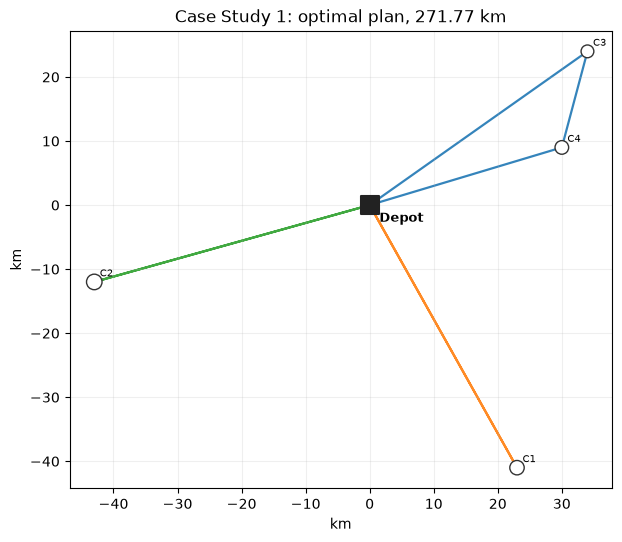

In [2]:
case1 = lg.Problem(
    customers=[lg.Customer("C1", 23, -41, 16), lg.Customer("C2", -43, -12, 19),
               lg.Customer("C3", 34, 24, 12), lg.Customer("C4", 30, 9, 14)],
    warehouses=[lg.Warehouse("Depot", 0, 0, trucks=3)],
    truck_capacity=28)  # cost_per_km defaults to 1, so cost = distance

result = lg.solve(case1, lg.GAParams(seed=SEED))
print(result.best.report(case1))
print(f"\nBrute force over every possible plan: {lg.brute_force(case1).total_cost:.2f} km")
lg.plot_plan(case1, result.best, title="Case Study 1: optimal plan, 271.77 km");

### 1.2 Re-running the report's 10 case studies

The data for every case study (report pp. 24–49) is in `data/report_case_studies.csv`. Fleet size, truck capacity, the stated total and the best chromosome from Table 33 are in `data/report_case_settings.csv`.

For each case, the cell below:
1. recomputes the distance of the report's best chromosome, which also checks the copied data;
2. runs the new GA on the same problem: same depot, fleet size and capacity, distance only.

In [3]:
def load_case_studies(customers_csv="data/report_case_studies.csv",
                      settings_csv="data/report_case_settings.csv"):
    with open(customers_csv, newline="") as f:
        rows = list(csv.DictReader(f))
    with open(settings_csv, newline="") as f:
        settings = list(csv.DictReader(f))
    cases = {}
    for s in settings:
        k = int(s["case"])
        customers = [lg.Customer(r["id"], float(r["x"]), float(r["y"]), float(r["demand"]))
                     for r in rows if int(r["case"]) == k]
        problem = lg.Problem(customers, [lg.Warehouse("Depot", 0, 0, trucks=int(s["vehicles"]))],
                             truck_capacity=float(s["capacity"]))
        cases[k] = {"problem": problem, "stated": float(s["reported_distance"]),
                    "chromosome": [int(g) for g in s["reported_chromosome"].split()]}
    return cases


def routes_from_report(n_customers, chromosome):
    # Report format: customers are 1..n; a vehicle id (> n) closes the route before it
    routes, stops = [], []
    for gene in chromosome:
        if gene > n_customers:
            routes.append((0, stops))
            stops = []
        else:
            stops.append(gene - 1)
    return routes


cases = load_case_studies()
print(f"{'Case':>4} {'Stores':>6} {'Trucks':>6} | {'Report (stated)':>15} {'Report (recomputed)':>19} | "
      f"{'New GA':>10} {'Saving':>7} {'Trucks used':>11} {'Time':>6}")
for k, case in cases.items():
    p = case["problem"]
    case["report"] = lg.price_routes(p, routes_from_report(p.n, case["chromosome"]))
    case["ga"] = lg.solve(p, lg.GAParams(seed=SEED))
    old, new = case["report"].km, case["ga"].best.km
    case["saving"] = 100 * (old - new) / old
    print(f"{k:>4} {p.n:>6} {p.warehouses[0].trucks:>6} | {case['stated']:>15,.2f} {old:>19,.2f} | "
          f"{new:>10,.2f} {case['saving']:>6.1f}% {len(case['ga'].best.routes):>6} of {p.warehouses[0].trucks:<3} "
          f"{case['ga'].seconds:>5.1f}s")

Case Stores Trucks | Report (stated) Report (recomputed) |     New GA  Saving Trucks used   Time


   1      4      3 |          271.77              271.77 |     271.77    0.0%      3 of 3     0.8s


   2      7      4 |        1,155.19            1,155.19 |   1,155.19    0.0%      4 of 4     0.3s


   3     10      6 |       24,908.65           24,908.65 |  23,518.55    5.6%      5 of 6     0.4s


   4     13     10 |       59,882.50           58,382.25 |  57,418.28    1.7%      6 of 10    0.4s


...

   6     19     15 |      134,207.21          134,207.21 | 113,908.76   15.1%      9 of 15    0.7s


   7     25     25 |      452,609.99          452,609.99 | 385,976.94   14.7%     14 of 25    0.7s


   8     30     27 |        6,782.40            6,782.40 |   5,025.71   25.9%      5 of 27    4.2s


   9     35     32 |       18,104.84           18,104.84 |  16,846.93    6.9%      5 of 32    6.6s


  10     40     34 |        8,300.26            8,300.26 |   4,152.15   50.0%      5 of 34    8.7s


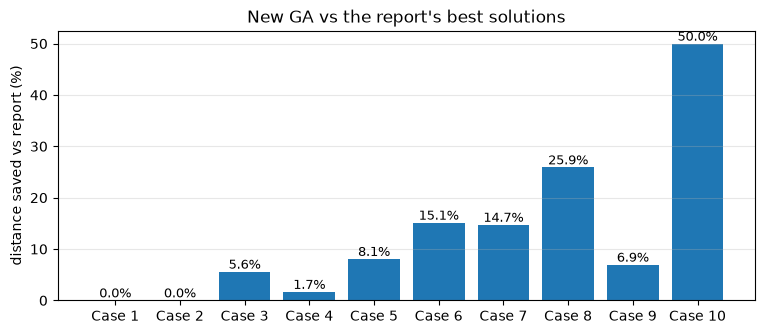

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar([f"Case {k}" for k in cases], [c["saving"] for c in cases.values()], color="#1f77b4")
for i, c in enumerate(cases.values()):
    ax.annotate(f"{c['saving']:.1f}%", (i, c["saving"]), ha="center", va="bottom", fontsize=9)
ax.set_ylabel("distance saved vs report (%)")
ax.set_title("New GA vs the report's best solutions")
ax.grid(axis="y", alpha=0.3);

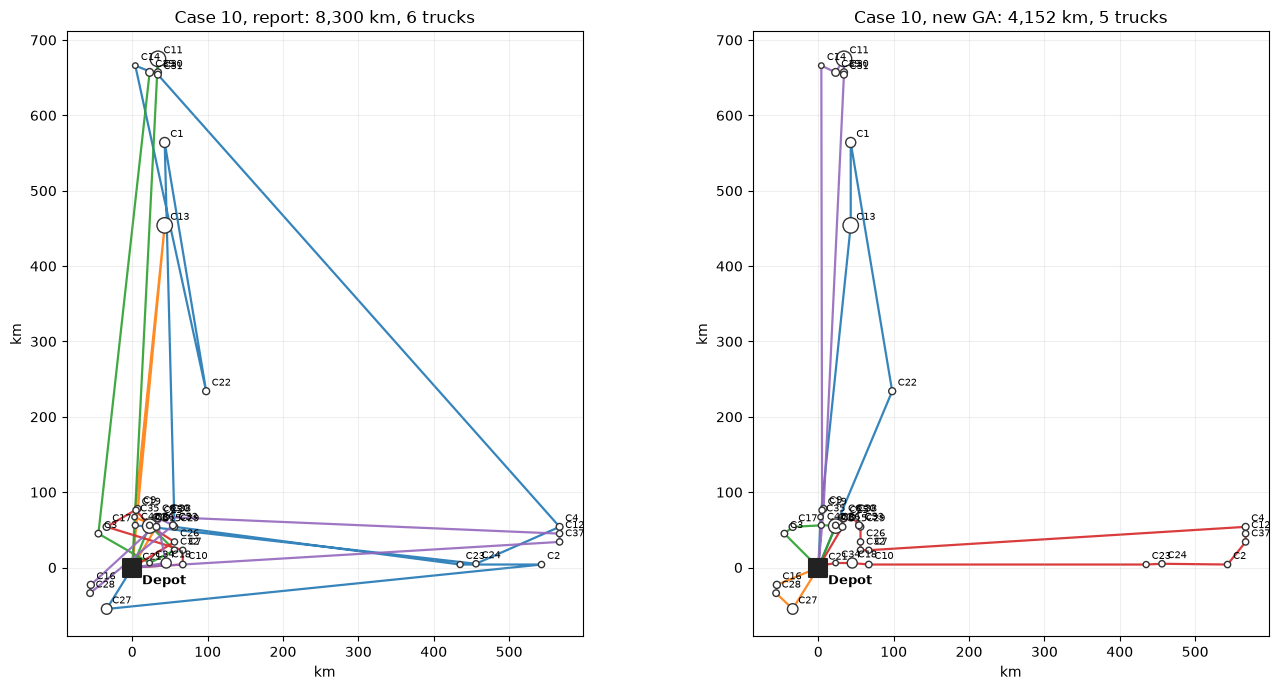

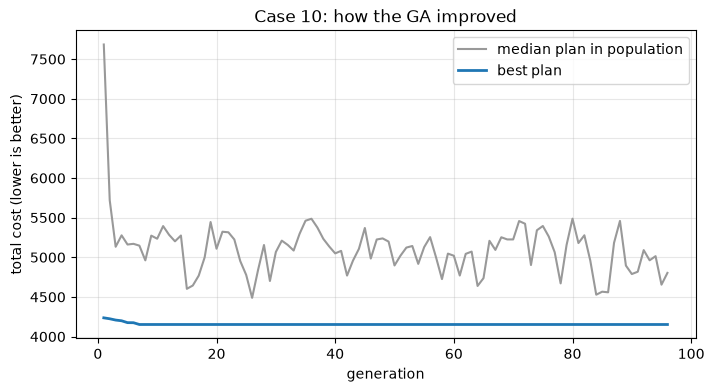

In [5]:
p10 = cases[10]["problem"]
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
lg.plot_plan(p10, cases[10]["report"], ax=axes[0],
             title=f"Case 10, report: {cases[10]['report'].km:,.0f} km, {len(cases[10]['report'].routes)} trucks")
lg.plot_plan(p10, cases[10]["ga"].best, ax=axes[1],
             title=f"Case 10, new GA: {cases[10]['ga'].best.km:,.0f} km, {len(cases[10]['ga'].best.routes)} trucks")
plt.tight_layout()
lg.plot_convergence(cases[10]["ga"], title="Case 10: how the GA improved");

**What this shows**

* On Case Studies 1 and 2 both GAs reach the same distance. For Case 1 that is the proven optimum.
* From Case 3 onwards the new GA finds shorter plans, and the gap grows with problem size. The main reasons, from the table above:
  * the population is 60 instead of 10;
  * Split chooses where to break the giant tour into trips, so the GA never wastes time on infeasible chromosomes;
  * tournament selection favours good parents;
  * local search removes detours, such as crossing routes.
* Every run takes seconds, and repeated runs with other seeds give the same or nearly the same answer.

**Two small slips in the report**, worth fixing if the report is reused. In both cases the recomputed column matches the report's own per-vehicle distances, so only the stated total is off:
* **Case 4:** the per-vehicle distances add up to 58,382.23 km, but the stated total is 59,882.50 km.
* **Case 5:** the per-vehicle distances add up to 15,029.14 km, but the stated total is 15,031.38 km.

## Part 2: Multi-depot VRP with stock limits

This is the report's first future research direction. A distributor serves **30 retail stores** in a 100 × 100 km region (three towns plus a few rural stores) from **four warehouses**:

* Each warehouse has limited **stock** today and its own **trucks**.
* Trucks carry **100 units**.
* Store **C05** is a large retailer ordering **130 units**, more than a truckload. It gets one full truck plus a share of another.

The objective is the same as in the report: **minimise total distance**. The GA now also decides which warehouse serves each store.

WH-Central  at (50, 50)   stock 600 units   8 trucks
WH-West     at (18, 58)   stock 350 units   5 trucks
WH-North    at (70, 88)   stock 300 units   5 trucks
WH-South    at (66, 12)   stock 300 units   5 trucks

30 stores order 868 units in total


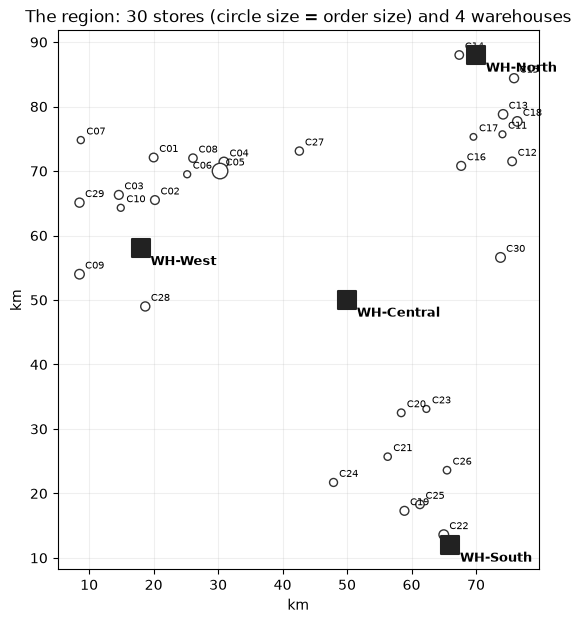

In [6]:
network = lg.load_problem("data/customers.csv", "data/warehouses.csv", truck_capacity=100)
# Part 2 is about distance only, so leave out the warehouses' running costs for now
mdvrp = lg.Problem(network.customers, [replace(w, fixed_cost=0) for w in network.warehouses],
                   truck_capacity=100)

for w in mdvrp.warehouses:
    print(f"{w.id:11s} at ({w.x:g}, {w.y:g})   stock {w.stock:g} units   {w.trucks} trucks")
print(f"\n{mdvrp.n} stores order {mdvrp.total_demand:g} units in total")
lg.plot_plan(mdvrp, None, title="The region: 30 stores (circle size = order size) and 4 warehouses");

**Why stock matters.** If every store were simply served by its nearest warehouse:

In [7]:
wanted = {w.id: 0.0 for w in mdvrp.warehouses}
for c, store in enumerate(mdvrp.customers):
    wanted[mdvrp.warehouses[mdvrp.nearest[c][0]].id] += store.demand
for w in mdvrp.warehouses:
    note = "   <-- not enough stock" if wanted[w.id] > w.stock else ""
    print(f"{w.id:11s} would have to ship {wanted[w.id]:4g} units but holds {w.stock:g}{note}")

WH-Central  would have to ship   91 units but holds 600
WH-West     would have to ship  422 units but holds 350   <-- not enough stock
WH-North    would have to ship  208 units but holds 300
WH-South    would have to ship  147 units but holds 300


Some West-town stores therefore *have* to be served from another warehouse. Which ones to move is part of what the GA optimises.

We compare the GA with a **rule of thumb** a planner might use by hand: biggest orders first, each to the nearest warehouse that still has stock, then each truck drives to the nearest unvisited store.

In [8]:
rule2 = lg.baseline(mdvrp)
part2 = lg.solve(mdvrp, lg.GAParams(seed=SEED))
print(f"Rule of thumb: {rule2.km:,.1f} km   GA: {part2.best.km:,.1f} km   "
      f"({100 * (rule2.km - part2.best.km) / rule2.km:.1f}% less driving)\n")
print(part2.best.report(mdvrp))

Rule of thumb: 495.0 km   GA: 443.2 km   (10.5% less driving)

WH-Central: ships 167 of 600 units, uses 2 of 8 trucks
  truck 1: WH-Central -> C30 -> C23 -> C20 -> WH-Central | load 68/100 | 74.2 km
  truck 2: WH-Central -> C06 -> C08 -> C04 -> C27 -> WH-Central | load 99/100 | 75.1 km
WH-West: ships 346 of 350 units, uses 4 of 5 trucks
  truck 1: WH-West -> C05 -> WH-West | load 100/100 | 34.4 km  (full truck)
  truck 2: WH-West -> C09 -> C28 -> WH-West | load 71/100 | 30.7 km
  truck 3: WH-West -> C02 -> C01 -> C05 -> WH-West | load 87/100 | 42.1 km
  truck 4: WH-West -> C10 -> C03 -> C07 -> C29 -> WH-West | load 88/100 | 41.0 km
WH-North: ships 208 of 300 units, uses 3 of 5 trucks
  truck 1: WH-North -> C15 -> C12 -> C16 -> C17 -> WH-North | load 98/100 | 45.3 km
  truck 2: WH-North -> C14 -> WH-North | load 26/100 | 5.2 km
  truck 3: WH-North -> C13 -> C11 -> C18 -> WH-North | load 84/100 | 28.4 km
WH-South: ships 147 of 300 units, uses 2 of 5 trucks
  truck 1: WH-South -> C25 -> C

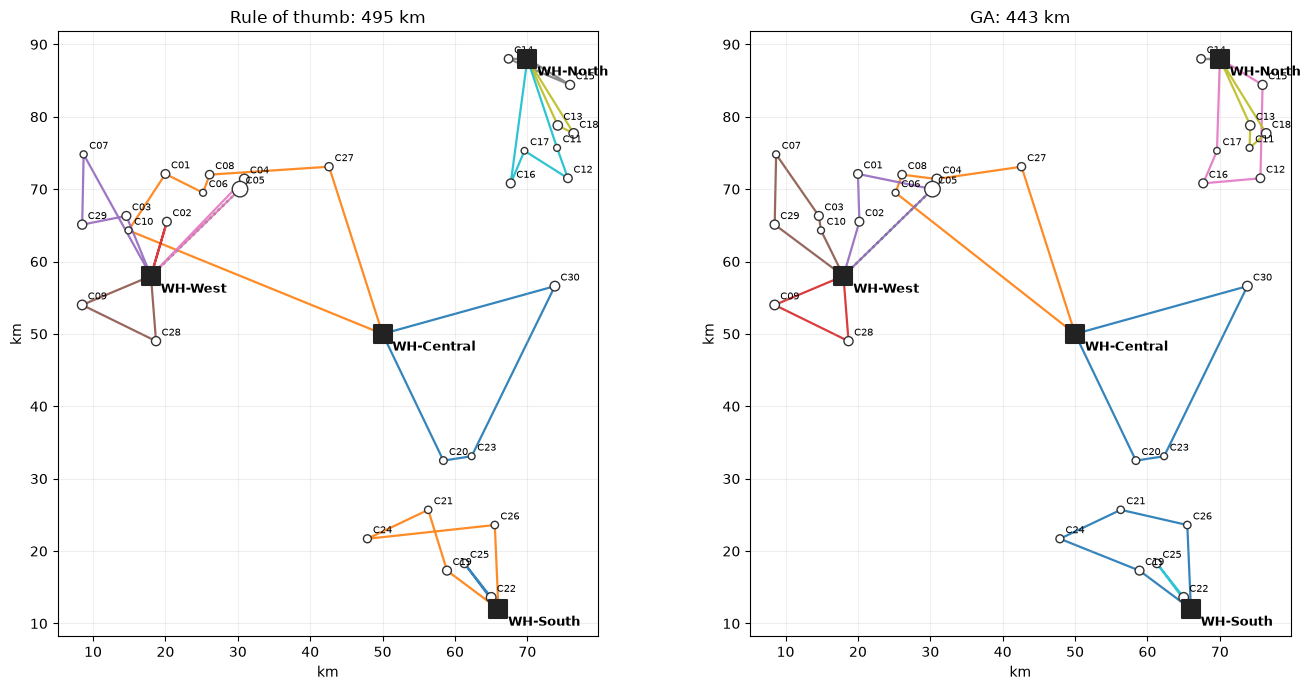

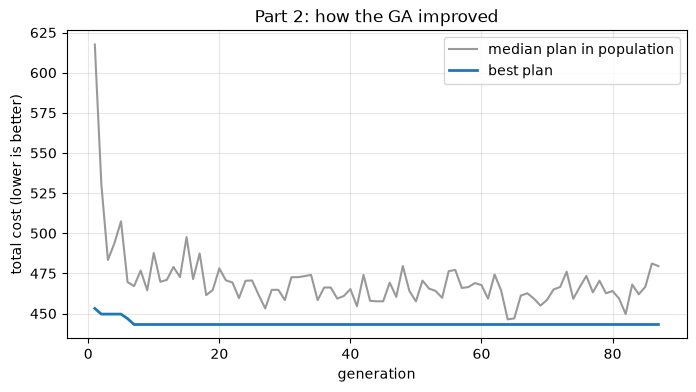

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
lg.plot_plan(mdvrp, rule2, ax=axes[0], title=f"Rule of thumb: {rule2.km:,.0f} km")
lg.plot_plan(mdvrp, part2.best, ax=axes[1], title=f"GA: {part2.best.km:,.0f} km")
plt.tight_layout()
lg.plot_convergence(part2, title="Part 2: how the GA improved");

**Reading the result**

* All four warehouses are used. Distance is the only cost, and every extra warehouse brings some stores closer.
* WH-West has less stock than its nearby stores need. Some West-town stores are served by WH-Central, as many as the stock allows and no more.
* The big order C05 stays with its nearest warehouse. Moving it would cost two long trips, not one, so it claims stock first.
* The GA also beats the rule of thumb by packing trucks better and uncrossing routes.

## Part 3: Which warehouses should we run? (location-routing)

Now we put money on everything:

* **Running a warehouse** costs rent, staff and power per day. See `fixed_cost` below; the big central site costs most.
* **Driving** costs **₹40 per km**: fuel, wear and driver time.
* **Sending out a truck** costs **₹2,000**: the driver's day and loading.

Opening a warehouse is now a real decision: it shortens deliveries but adds its running cost. The stock and truck limits from Part 2 still apply. The GA minimises the total daily cost.

In [10]:
COSTS = dict(cost_per_km=40, cost_per_truck=2000)
lrp = lg.Problem(network.customers, network.warehouses, truck_capacity=100, **COSTS)
for w in lrp.warehouses:
    print(f"{w.id:11s} running cost ₹{w.fixed_cost:,.0f}/day   stock {w.stock:g}")

rule3 = lg.baseline(lrp)
part3 = lg.solve(lrp, lg.GAParams(seed=SEED))
# Part 2's shortest-distance network and allocation, priced with the new costs
distance_plan = lg.decode(lrp, part2.order, part2.assign)

print(f"\nRule of thumb (every warehouse open):  ₹{rule3.total_cost:,.0f}")
print(f"Shortest-distance plan from Part 2:    ₹{distance_plan.total_cost:,.0f}")
print(f"GA, cost-optimal plan:                 ₹{part3.best.total_cost:,.0f}   "
      f"({100 * (rule3.total_cost - part3.best.total_cost) / rule3.total_cost:.1f}% cheaper than the rule of thumb)\n")
print(part3.best.report(lrp))

WH-Central  running cost ₹10,000/day   stock 600
WH-West     running cost ₹7,000/day   stock 350
WH-North    running cost ₹6,000/day   stock 300
WH-South    running cost ₹5,000/day   stock 300



Rule of thumb (every warehouse open):  ₹69,861
Shortest-distance plan from Part 2:    ₹67,727
GA, cost-optimal plan:                 ₹59,505   (14.8% cheaper than the rule of thumb)

WH-West: ships 346 of 350 units, uses 4 of 5 trucks
  truck 1: WH-West -> C05 -> WH-West | load 100/100 | 34.4 km  (full truck)
  truck 2: WH-West -> C10 -> C03 -> C07 -> C29 -> WH-West | load 88/100 | 41.0 km
  truck 3: WH-West -> C09 -> C28 -> WH-West | load 71/100 | 30.7 km
  truck 4: WH-West -> C02 -> C01 -> C05 -> WH-West | load 87/100 | 42.1 km
WH-North: ships 284 of 300 units, uses 3 of 5 trucks
  truck 1: WH-North -> C15 -> C11 -> C12 -> C16 -> WH-North | load 100/100 | 45.5 km
  truck 2: WH-North -> C08 -> C06 -> C04 -> C17 -> WH-North | load 85/100 | 107.0 km
  truck 3: WH-North -> C18 -> C13 -> C14 -> WH-North | load 99/100 | 28.6 km
WH-South: ships 238 of 300 units, uses 3 of 5 trucks
  truck 1: WH-South -> C25 -> C23 -> C20 -> C21 -> C19 -> WH-South | load 100/100 | 51.4 km
  truck 2: WH-Sout

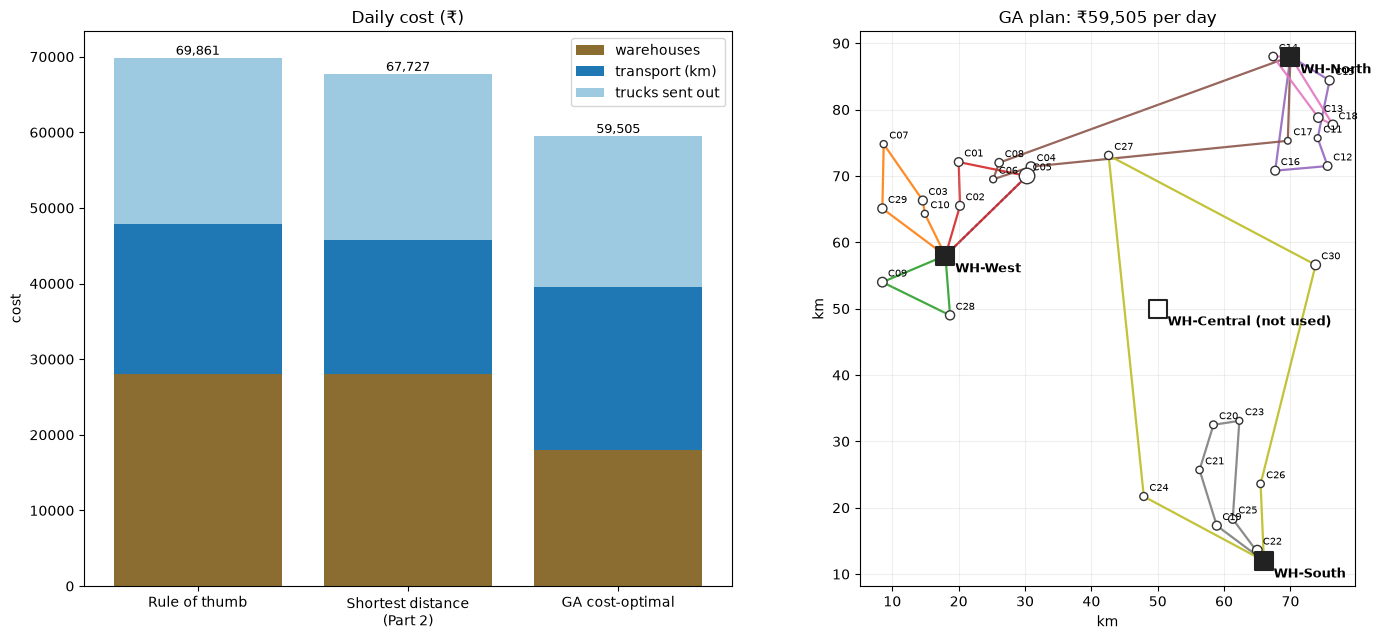

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1, 1.15]})
lg.plot_costs({"Rule of thumb": rule3, "Shortest distance\n(Part 2)": distance_plan,
               "GA cost-optimal": part3.best}, ax=axes[0], title="Daily cost (₹)")
lg.plot_plan(lrp, part3.best, ax=axes[1], title=f"GA plan: ₹{part3.best.total_cost:,.0f} per day")
plt.tight_layout()

**Reading the result**

* The cheapest network is **not** the one with the shortest distance. Closing a warehouse makes trucks drive further, but saves more in running cost than the extra kilometres cost.
* The central warehouse holds the most stock, but it is the expensive one, and three regional warehouses together hold enough stock. So the GA runs the regional sites and leaves Central unused.
* This is the core trade-off in distribution network design: **facility cost vs transport cost**. Part 4 explores it.

## Part 4: Experiment: how rent shapes the network

The warehouses' running costs are scaled from free (×0) up to six times today's level (×6), and the GA is re-run each time. Everything else stays the same.

In [12]:
multipliers = [0, 0.25, 0.5, 1, 2, 4, 6]
sweep = []
for k in multipliers:
    p = lg.Problem(network.customers, [replace(w, fixed_cost=w.fixed_cost * k) for w in network.warehouses],
                   truck_capacity=100, **COSTS)
    best = lg.solve(p, lg.GAParams(seed=SEED)).best
    names = [p.warehouses[w].id.removeprefix("WH-") for w in best.open_warehouses]
    sweep.append((k, best, names))
    print(f"rent x{k:<4g} run {' + '.join(names):30s} rent ₹{best.fixed_cost:>7,.0f}   "
          f"delivery ₹{best.transport_cost + best.truck_cost:>7,.0f}   total ₹{best.total_cost:>8,.0f}")

rent x0    run Central + West + North + South rent ₹      0   delivery ₹ 38,225   total ₹  38,225


rent x0.25 run Central + West + North + South rent ₹  7,000   delivery ₹ 37,835   total ₹  44,835


rent x0.5  run West + North + South           rent ₹  9,000   delivery ₹ 41,505   total ₹  50,505


rent x1    run West + North + South           rent ₹ 18,000   delivery ₹ 41,505   total ₹  59,505


rent x2    run West + North + South           rent ₹ 36,000   delivery ₹ 41,505   total ₹  77,505


rent x4    run Central + North                rent ₹ 64,000   delivery ₹ 47,883   total ₹ 111,883


rent x6    run Central + South                rent ₹ 90,000   delivery ₹ 49,792   total ₹ 139,792


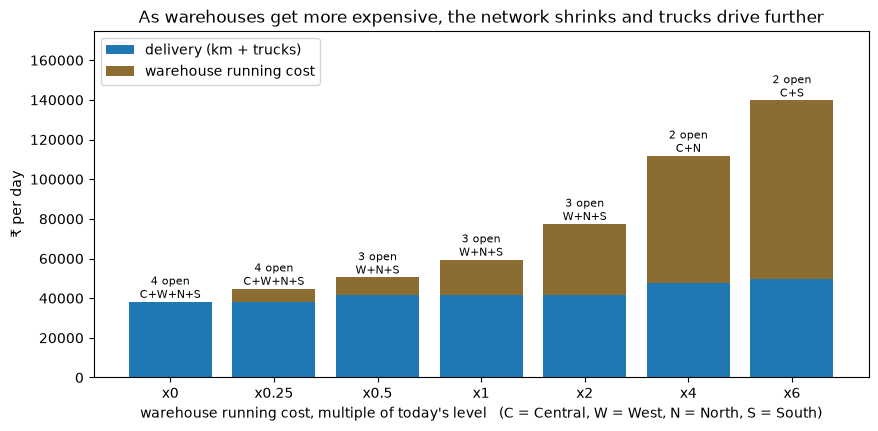

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
labels = [f"x{k:g}" for k, _, _ in sweep]
rent = [s.fixed_cost for _, s, _ in sweep]
delivery = [s.transport_cost + s.truck_cost for _, s, _ in sweep]
ax.bar(labels, delivery, color="#1f77b4", label="delivery (km + trucks)")
ax.bar(labels, rent, bottom=delivery, color="#8c6d31", label="warehouse running cost")
for i, (_, s, names) in enumerate(sweep):
    ax.annotate(f"{len(names)} open\n{'+'.join(n[0] for n in names)}", (i, s.total_cost),
                ha="center", va="bottom", fontsize=8)
ax.set_xlabel("warehouse running cost, multiple of today's level   (C = Central, W = West, N = North, S = South)")
ax.set_ylabel("₹ per day")
ax.set_ylim(0, max(s.total_cost for _, s, _ in sweep) * 1.25)
ax.set_title("As warehouses get more expensive, the network shrinks and trucks drive further")
ax.legend(loc="upper left");

**Reading the result**

* **Free warehouses:** use all of them. Delivery cost is lowest when every store is close to stock.
* **Moderate rent:** three regional warehouses win. Central is the priciest site and is not needed when the other three hold enough stock.
* **Expensive rent:** centralise to two warehouses, the fewest that can hold all 868 units. Every such pair has to include Central, because no two regional sites have enough stock between them.
* Delivery cost (blue) rises as the network shrinks, while rent cost (brown) is held down. This is the classic shape behind questions like "how many warehouses should we have?".
* **Near ties are real.** At ×4, Central + North and Central + South cost within about 1% of each other, so another random seed may pick the other pair. When options are that close, things the model leaves out should decide: delivery times, lease terms, room to grow.

## Part 5: Use your own data

Two CSV files:

* **customers** – `id,x,y,demand`
* **warehouses** – `id,x,y,stock,fixed_cost,trucks`. A blank `stock` or `trucks` means no limit; a blank `fixed_cost` means 0.

```python
p = lg.load_problem("my_customers.csv", "my_warehouses.csv", truck_capacity=100,
                    cost_per_km=40, cost_per_truck=2000)
result = lg.solve(p, lg.GAParams(seed=1))
print(result.best.report(p))
lg.plot_plan(p, result.best)
```

The same from a terminal, saving a map:

```
python logistics_ga.py my_customers.csv my_warehouses.csv --capacity 100 --cost-per-km 40 --cost-per-truck 2000 --plot plan.png
```

* `lg.problem_from_input()` asks for the data at the keyboard, like the original notebook.
* For real road distances instead of straight lines, pass `distance_matrix=` to `lg.Problem`. Rows and columns are the customers first, then the warehouses.
* GA settings, all optional: `lg.GAParams(population_size=60, max_generations=400, stall_generations=80, crossover_rate=0.9, mutation_rate=0.4, elite_count=2, tournament_size=3, local_search_rate=0.2, seed=None)`.

## Takeaways for supply-chain understanding

1. **Routing:** better routes alone cut distance noticeably. The re-run case studies saved up to 50% against the report's results, and Part 2 beat the rule of thumb.
2. **Inventory:** stock limits change who serves whom. The nearest warehouse is not always possible, and the GA picks which stores to move so that the least extra distance is added.
3. **Network design:** the cheapest network balances facility cost against transport cost. The shortest-distance plan is not the cheapest one.
4. **Method:** a GA with a smart decoder (Split, stock claiming) and a little local search is fast and reliable on these sizes. For tiny problems, `lg.brute_force` proves the optimum.

**Further extensions**, in line with the report's future research list: vehicles with different capacities and costs (heterogeneous fleet), delivery time windows (VRPTW), road-network distances via `distance_matrix`, two-echelon networks (warehouse → hub → store), and multi-objective GAs that trade cost against delivery time or CO₂.